# 40. 예측·분류 모델과 우선 지원 알고리즘(Q3)

설명자료의 모델링 요건: "상권별 기후 영향 및 피해 규모 예측·분류 모델 개발, 성능평가, 재현 가능한 코드".

| 모델 | 무엇을 | 입력 | 검증 |
|---|---|---|---|
| A. 일 매출 예측(LightGBM 회귀) | 지역×업종의 일 매출. 직전 4주 같은 요일 평균(단순 예측)을 기준으로, 그 기준에서 얼마나 벗어나는지를 학습 | 달력, 7일 이상 지난 과거 매출, 업종 구조, 날씨(+다음 날 강수 예보 대리) | 월 단위 교차검증(6겹) + 앞으로 예측(7~10월 학습 → 11~12월) |
| B. 이벤트일 경보 분류(LightGBM 분류) | 이벤트일에 그 상권 매출이 평상시보다 10% 이상 줄어들지 | 업종 구조, 이벤트 강도(시간대별 강수, 기온, 밤 최저), 요일 | 날짜 단위 GroupKFold(5겹) |
| C. 우선 지원 순위 | 예보 시나리오에서 누구를 먼저 지원할지 | B의 확률 × 예상 손실(30번 민감도 × 그 요일 평상 매출) | 시나리오 2개 |

성능 비교 기준선: 직전 4주 같은 요일 평균(계절 단순 예측), 날씨 없는 동일 모델. 해석은 LightGBM 내장 SHAP(pred_contrib).
거래가 없는 날(매출 0)은 휴업·결측으로 보고 뺀다.

출력: `outputs/tables/m_*.csv`, 그림 `m*.png`

In [1]:
import sys
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, mean_absolute_error, r2_score, roc_auc_score
from sklearn.model_selection import GroupKFold

sys.path.insert(0, str(Path.cwd()))
from common import (FIG, TAB, REGIONS, REGION_NAME, TIME_BANDS, TB_NAME, FACE_GROUPS, load)
from analysis import (RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, EVENT_COLOR, exclusion_days, deviation, finish)

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 80)
SEED = 42

cal = load("calendar"); EXCL = exclusion_days(cal)
panel = load("model_panel_day")
wtb = load("weather_tb")
rn_tb = wtb.pivot_table(index=["region", "date"], columns="tb", values="rn_sum").reindex(columns=TIME_BANDS).fillna(0)
rn_tb.columns = [f"w_rn_{t[:2]}" for t in TIME_BANDS]
panel = panel.merge(rn_tb.reset_index(), on=["region", "date"], how="left")
d = panel[(panel.in_scope == 1) & (panel.sales > 0)].copy()
d["series"] = d.region + "|" + d.industry
d["face"] = d.group.isin(FACE_GROUPS).astype(int)
d = d.rename(columns={"p_share_age_10-20대": "p_age_young", "p_share_age_30-50대": "p_age_mid", "p_share_age_60대+": "p_age_old"})
# 과거 매출 피처를 기준선(4주 같은 요일 평균) 대비 상대값으로
d["h_lag7"] = d.y_lag7 - d.y_dow_mean4
d["h_lag14"] = d.y_lag14 - d.y_dow_mean4
d["h_ma7"] = d.y_ma7_lag7 - d.y_dow_mean4
d["r"] = d.y - d.y_dow_mean4  # 학습 목표: 기준선 대비 편차(로그)
for c in ["region", "industry", "group"]:
    d[c] = d[c].astype("category")

CAT = ["region", "industry", "group"]
CAL = ["dow", "is_holiday", "is_pre_long_off", "is_post_long_off", "is_sandwich", "is_special", "is_chuseok_block",
       "coupon_phase", "is_coupon_last_week", "days_to_month_end", "off_block_len", "off_block_pos", "payback_on"]
HIST = ["y_dow_mean4", "h_lag7", "h_lag14", "h_ma7"]
PROF = ["p_ticket", "p_share_tb_00_05", "p_share_tb_06_11", "p_share_tb_12_17", "p_share_tb_18_23", "p_age_young", "p_age_mid", "p_age_old",
        "p_share_sex_F", "p_ratio_weekend", "p_share_nonlocal", "small_biz", "outdoor", "discretionary"]
WX = ["w_ta_max_off", "w_feels_max", "w_night_min", "w_rn_biz", "w_rn_sum", "w_rn_biz_hours", "w_rn_06", "w_rn_12", "w_rn_18", "w_hm_mean",
      "w_heat_day", "w_tropical", "w_rain_biz10", "w_rn_biz_lag1", "w_rn_biz_lead1", "w_heat_streak", "w_ta_max_anom31"]
FEAT_FULL = CAT + CAL + HIST + PROF + WX
FEAT_NOW = CAT + CAL + HIST + PROF
FAMILY = {**{c: "업종·지역" for c in CAT + PROF}, **{c: "달력" for c in CAL}, **{c: "과거 매출" for c in HIST}, **{c: "날씨" for c in WX}}
dm = d.dropna(subset=["r"]).copy()  # 기준선이 있는 행(5주차부터)
print(f"행 {len(d):,} (기준선 있는 행 {len(dm):,}), 시리즈 {d.series.nunique()}, 피처 {len(FEAT_FULL)}개(날씨 {len(WX)}개)")

행 25,888 (기준선 있는 행 24,901), 시리즈 141, 피처 51개(날씨 17개)


## A. 일 매출 예측 모델

목표 변수는 log(1+매출) − 직전 4주 같은 요일 평균(로그). 즉 단순 예측에서 얼마나 벗어나는지를 달력·업종·날씨로 설명한다. 과거 매출 피처는 7일 이상 지난 값만 써서 최대 7일 앞 예보와 함께 쓸 수 있게 한다.

In [2]:
PARAMS = dict(n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=2.0, random_state=SEED, verbose=-1)

def fit_predict(train, test, feats):
    m = lgb.LGBMRegressor(**PARAMS)
    m.fit(train[feats], train.r, categorical_feature=[c for c in CAT if c in feats])
    return m, test.y_dow_mean4.values + m.predict(test[feats])

def metrics(df, pred_col):
    out = {}
    for name, sub in [("전체", df), ("대면소비", df[df.face == 1]), ("비 10mm+ 날", df[(df.face == 1) & (df.w_rain_biz10 == 1)]),
                      ("폭염일", df[(df.face == 1) & (df.w_heat_day == 1)]), ("열대야", df[(df.face == 1) & (df.w_tropical == 1)])]:
        s = sub.dropna(subset=[pred_col, "y"])
        if len(s) < 30:
            out[name] = {"MAE(log)": np.nan, "R2(log)": np.nan, "WAPE(%)": np.nan, "편향(%)": np.nan, "n": len(s)}
            continue
        err = np.expm1(s[pred_col]) - s.sales
        out[name] = {"MAE(log)": mean_absolute_error(s.y, s[pred_col]), "R2(log)": r2_score(s.y, s[pred_col]),
                     "WAPE(%)": np.abs(err).sum() / s.sales.sum() * 100, "편향(%)": err.sum() / s.sales.sum() * 100, "n": len(s)}
    return pd.DataFrame(out).T

# 1) 월 단위 교차검증: 한 달을 빼고 나머지로 학습
dm["pred_full"], dm["pred_now"] = np.nan, np.nan
for m_ in sorted(dm.month.unique()):
    tr, te = dm[dm.month != m_], dm[dm.month == m_]
    _, dm.loc[te.index, "pred_full"] = fit_predict(tr, te, FEAT_FULL)
    _, dm.loc[te.index, "pred_now"] = fit_predict(tr, te, FEAT_NOW)
dm["pred_naive"] = dm.y_dow_mean4
cv = pd.concat({"LightGBM(날씨 포함)": metrics(dm, "pred_full"), "LightGBM(날씨 제외)": metrics(dm, "pred_now"), "기준선(4주 같은 요일 평균)": metrics(dm, "pred_naive")}, names=["모델", "구간"])
cv.round(3).to_csv(TAB / "m_cv_month.csv", encoding="utf-8-sig")
cv.round(3)

MAE(log)  R2(log)  WAPE(%)  편향(%)        n
모델               구간                                                   
LightGBM(날씨 포함)  전체            0.343    0.921   17.029 -3.941  24901.0
                 대면소비          0.332    0.916   15.762 -2.827  17844.0
                 비 10mm+ 날     0.397    0.876   19.162 -5.157   1902.0
                 폭염일           0.323    0.924   14.361 -1.377   2614.0
                 열대야           0.278    0.936   13.416  0.062   2203.0
LightGBM(날씨 제외)  전체            0.340    0.923   16.708 -2.839  24901.0
                 대면소비          0.328    0.917   15.538 -1.811  17844.0
                 비 10mm+ 날     0.397    0.874   19.647  5.554   1902.0
                 폭염일           0.317    0.926   13.578 -1.875   2614.0
                 열대야           0.272    0.938   12.929 -0.075   2203.0
기준선(4주 같은 요일 평균) 전체            0.363    0.909   18.736 -4.251  24901.0
                 대면소비          0.346    0.906   15.804 -2.967  17844.0
                 비 10mm+ 날     0.414    0.863   20.158  4.362   1902.0
                 폭염일           0.334    0.913   13.828 -2.692   2614.0
                 열대야           0.285    0.932   12.939 -1.449   2203.0

날씨 피처의 가치는 평범한 날보다 이벤트일에서 나타나야 한다. '비 10mm+ 날' 행에서 날씨 포함 모델의 오차·편향이 줄어드는지 본다(기준선은 비 온 날 매출을 과대 예측해 편향이 +로 나온다).

In [3]:
# 2) 앞으로 예측: 7~10월 학습 → 11~12월 검증
tr, te = dm[dm.month <= 10], dm[dm.month >= 11].copy()
m_full, te["pred_full"] = fit_predict(tr, te, FEAT_FULL)
m_now, te["pred_now"] = fit_predict(tr, te, FEAT_NOW)
te["pred_naive"] = te.y_dow_mean4
fwd = pd.concat({"LightGBM(날씨 포함)": metrics(te, "pred_full"), "LightGBM(날씨 제외)": metrics(te, "pred_now"), "기준선": metrics(te, "pred_naive")}, names=["모델", "구간"])
fwd.round(3).to_csv(TAB / "m_forward.csv", encoding="utf-8-sig")
fwd.round(3).loc[(slice(None), ["전체", "대면소비", "비 10mm+ 날"]), :]

MAE(log)  R2(log)  WAPE(%)  편향(%)       n
모델              구간                                                  
LightGBM(날씨 포함) 전체            0.341    0.923   16.962  4.196  8584.0
                대면소비          0.328    0.917   15.353 -0.423  6154.0
                비 10mm+ 날       NaN      NaN      NaN    NaN     0.0
LightGBM(날씨 제외) 전체            0.329    0.926   15.202 -0.343  8584.0
                대면소비          0.319    0.919   15.202 -3.342  6154.0
                비 10mm+ 날       NaN      NaN      NaN    NaN     0.0
기준선             전체            0.342    0.919   16.320 -5.163  8584.0
                대면소비          0.331    0.911   14.999 -4.871  6154.0
                비 10mm+ 날       NaN      NaN      NaN    NaN     0.0

### 해석: 어떤 피처가 예측을 움직이나(SHAP)

LightGBM 내장 SHAP 값(pred_contrib)으로 피처 가족별 평균 기여 크기와, 비 온 날 날씨 피처의 기여(%)를 본다. 전체 기간 모델로 계산한다.

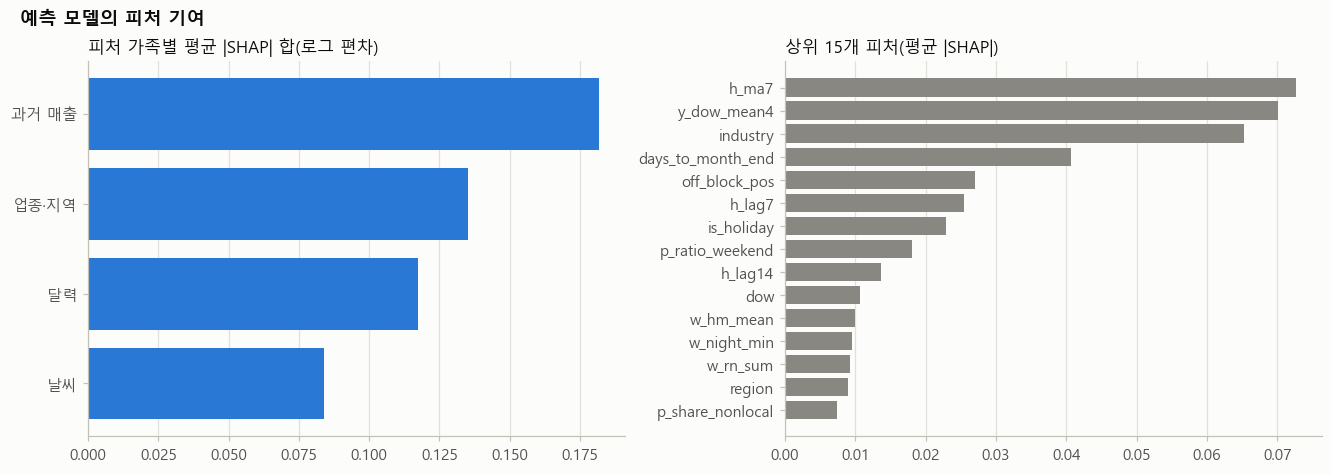

날씨 피처 기여의 평균(%, 대면소비, 조건별):


,비 없음(1mm 미만),비 10mm+,폭염일,열대야
region,,,,
chuncheon,1.6,-11.1,3.9,3.0
gangnam,2.0,-8.3,2.8,1.7


In [4]:
m_all = lgb.LGBMRegressor(**PARAMS).fit(dm[FEAT_FULL], dm.r, categorical_feature=CAT)
contrib = m_all.predict(dm[FEAT_FULL], pred_contrib=True)
shap = pd.DataFrame(contrib[:, :-1], columns=FEAT_FULL, index=dm.index)
fam = shap.abs().T.groupby(pd.Series(FAMILY)).sum().T.mean().sort_values(ascending=False)
top_feat = shap.abs().mean().sort_values(ascending=False).head(15)
fam.to_csv(TAB / "m_shap_family.csv", encoding="utf-8-sig"); top_feat.to_csv(TAB / "m_shap_top.csv", encoding="utf-8-sig")
dm["shap_wx"] = shap[WX].sum(axis=1)
wx_ev = {}
for name, mk in {"비 없음(1mm 미만)": dm.w_rn_biz < 1, "비 10mm+": dm.w_rain_biz10 == 1, "폭염일": dm.w_heat_day == 1, "열대야": dm.w_tropical == 1}.items():
    wx_ev[name] = dm[(dm.face == 1) & mk].groupby("region", observed=True).shap_wx.mean()
wx_ev = (np.exp(pd.DataFrame(wx_ev)) - 1) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
axes[0].barh(range(len(fam)), fam.values[::-1], color="#2a78d6"); axes[0].set_yticks(range(len(fam)), fam.index[::-1]); axes[0].set_title("피처 가족별 평균 |SHAP| 합(로그 편차)"); axes[0].grid(axis="y", visible=False)
axes[1].barh(range(len(top_feat)), top_feat.values[::-1], color="#898781"); axes[1].set_yticks(range(len(top_feat)), top_feat.index[::-1]); axes[1].set_title("상위 15개 피처(평균 |SHAP|)"); axes[1].grid(axis="y", visible=False)
finish(fig, FIG, "m01_shap", "예측 모델의 피처 기여")
plt.show()
print("날씨 피처 기여의 평균(%, 대면소비, 조건별):"); wx_ev.round(1)

### 교차 점검: 모델에 '비가 안 왔다'고 넣으면

학습한 모델에 비 온 날의 강수 피처만 0으로 바꿔 예측한 값과 실제 날씨 예측값의 차이를 손실로 본다. 기온은 계절과 얽혀 있어 반사실로 바꾸지 않는다(기온을 바꾸면 계절 효과가 섞인다). 30번의 회귀 기반 호우 손실과 비교한다.

In [5]:
cf = dm.copy()
for c in ["w_rn_biz", "w_rn_sum", "w_rn_biz_hours", "w_rn_06", "w_rn_12", "w_rn_18", "w_rain_biz10"]:
    cf[c] = 0
cf["w_hm_mean"] = cf.w_hm_mean.clip(upper=70)
dm["yhat_actual"] = dm.y_dow_mean4 + m_all.predict(dm[FEAT_FULL]); dm["yhat_norain"] = dm.y_dow_mean4 + m_all.predict(cf[FEAT_FULL])
dm["loss_model"] = np.expm1(dm.yhat_norain) - np.expm1(dm.yhat_actual)
x = dm[(dm.face == 1) & (dm.w_rain_biz10 == 1)]
ml = (x.groupby("region", observed=True).loss_model.sum() / 1e8).rename("모델 기반 호우 손실(억원)")
reg_loss = pd.read_csv(TAB / "v_summary_region.csv", encoding="utf-8-sig", index_col=0)
cmp_ = pd.concat([ml, reg_loss["손실_호우_억"].rename("회귀 기반 호우 손실(억원)")], axis=1)
cmp_["모델 기반 손실률(%)"] = ml / (x.groupby("region", observed=True).sales.sum() / 1e8 / (1 - 0)) * 100
cmp_.round(1).to_csv(TAB / "m_loss_compare.csv", encoding="utf-8-sig")
print("(모델 기반은 5주차 이후 비 온 날만 포함)"); cmp_.round(1)

(모델 기반은 5주차 이후 비 온 날만 포함)


,모델 기반 호우 손실(억원),회귀 기반 호우 손실(억원),모델 기반 손실률(%)
region,,,
chuncheon,123.1,95.1,11.1
gangnam,425.3,203.0,7.5


## B. 이벤트일 경보 분류 모델

관측 단위: 대면소비 시리즈 × 이벤트일(호우·폭염·열대야 중 하나라도). 라벨: 그날 매출이 평상시(같은 요일 앞뒤 2주 평균)보다 10% 이상 낮으면 1. 재난지원금 지급 기준(매출 10%/20% 감소)과 같은 문턱이다. 날짜로 묶은 5겹 교차검증.

In [6]:
face = d[d.face == 1].copy()
dev = deviation(face, ["region", "industry"], excl=EXCL)
dev["region"] = dev.region.astype(str); dev["industry"] = dev.industry.astype(str)
fb = face.assign(region=face.region.astype(str), industry=face.industry.astype(str)).merge(dev, on=["region", "industry", "date"])
ev = fb[(fb.w_rain_biz10 == 1) | (fb.w_heat_day == 1) | (fb.w_tropical == 1)].copy()
ev["label"] = (ev.dev <= np.log(0.9)).astype(int)
ev["label20"] = (ev.dev <= np.log(0.8)).astype(int)
for c in CAT:
    ev[c] = ev[c].astype("category")
CLS_FEAT = CAT + PROF + ["dow", "is_weekend", "w_ta_max_off", "w_feels_max", "w_night_min", "w_rn_biz", "w_rn_06", "w_rn_12", "w_rn_18",
                         "w_rn_biz_hours", "w_hm_mean", "w_heat_day", "w_tropical", "w_rain_biz10", "w_heat_streak", "w_rn_biz_lag1"]
CPARAMS = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
               reg_lambda=1.0, random_state=SEED, verbose=-1)
print(f"관측 {len(ev):,}건(시리즈 {ev.series.nunique()}개 × 이벤트일), 양성(10%+ 감소) 비율 {ev.label.mean():.1%}, 20%+ 감소 {ev.label20.mean():.1%}")
ev["p_hat"] = np.nan
gkf = GroupKFold(n_splits=5)
for tr_i, te_i in gkf.split(ev, ev.label, groups=ev.date):
    clf = lgb.LGBMClassifier(**CPARAMS).fit(ev.iloc[tr_i][CLS_FEAT], ev.iloc[tr_i].label, categorical_feature=CAT)
    ev.iloc[te_i, ev.columns.get_loc("p_hat")] = clf.predict_proba(ev.iloc[te_i][CLS_FEAT])[:, 1]
ev["p_rule"] = ((ev.region.astype(str) == "chuncheon") & (ev.w_rain_biz10 == 1)).astype(float)  # 단순 규칙 기준선
def cls_metrics(y, p):
    k = int(len(y) * 0.2); top = np.argsort(-p)[:k]
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "양성 비율": y.mean(),
            "정밀도@상위20%": y.iloc[top].mean(), "재현율@상위20%": y.iloc[top].sum() / y.sum()}
res = pd.DataFrame({"LightGBM": cls_metrics(ev.label, ev.p_hat.values), "규칙(춘천&비10mm+)": cls_metrics(ev.label, ev.p_rule.values)}).T
by_ev = {}
for name, mk in {"호우일": ev.w_rain_biz10 == 1, "폭염일": ev.w_heat_day == 1, "열대야": ev.w_tropical == 1}.items():
    s = ev[mk]
    by_ev[name] = {"n": len(s), "양성 비율": s.label.mean(), "ROC-AUC": roc_auc_score(s.label, s.p_hat) if s.label.nunique() > 1 else np.nan}
res.round(3).to_csv(TAB / "m_cls_metrics.csv", encoding="utf-8-sig")
pd.DataFrame(by_ev).T.round(3).to_csv(TAB / "m_cls_by_event.csv", encoding="utf-8-sig")
print(res.round(3)); pd.DataFrame(by_ev).T.round(3)

관측 5,468건(시리즈 101개 × 이벤트일), 양성(10%+ 감소) 비율 32.9%, 20%+ 감소 21.1%


C:\Users\nk233\Desktop\YBIGTA\26-2학기\학기중\빅콘\code\analysis.py:37: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = np.log1p(df.pivot_table(index="date", columns=keys, values=value, aggfunc="sum")).reindex(DATES)


               ROC-AUC  PR-AUC  양성 비율  정밀도@상위20%  재현율@상위20%
LightGBM         0.680   0.480  0.329      0.483      0.293
규칙(춘천&비10mm+)    0.568   0.376  0.329      0.484      0.294


,n,양성 비율,ROC-AUC
호우일,1604.0,0.471,0.619
폭염일,2715.0,0.269,0.681
열대야,2617.0,0.268,0.653


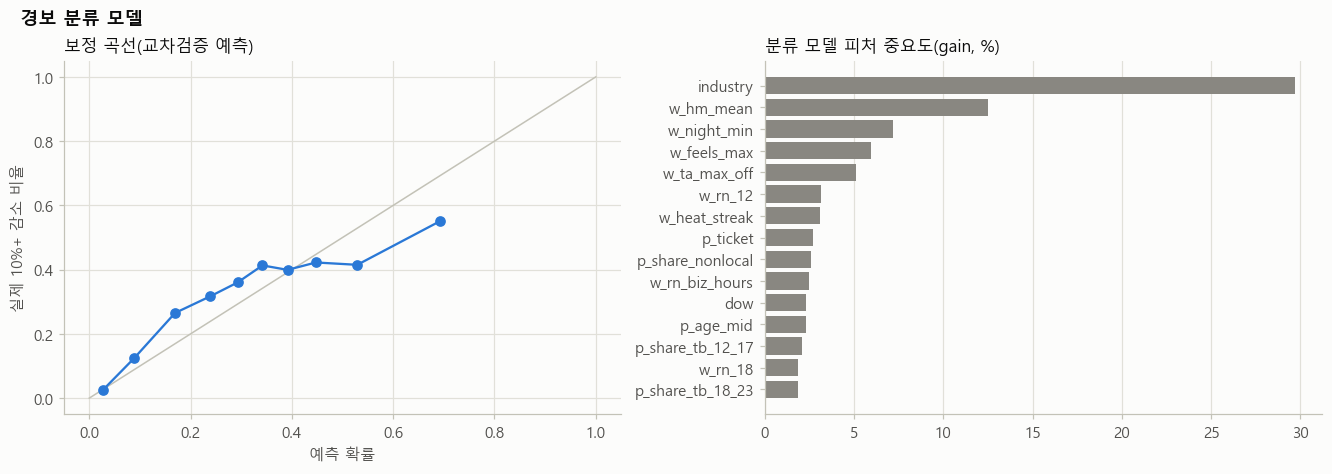

,예측확률,실제비율,n
bin,,,
0,0.027,0.026,547
1,0.089,0.124,547
2,0.169,0.265,547
3,0.239,0.317,546
4,0.293,0.360,547
5,0.342,0.413,547
6,0.392,0.399,546
7,0.447,0.422,547
8,0.529,0.415,547


In [7]:
# 보정(calibration)과 피처 중요도
ev["bin"] = pd.qcut(ev.p_hat, 10, labels=False, duplicates="drop")
calib = ev.groupby("bin").agg(예측확률=("p_hat", "mean"), 실제비율=("label", "mean"), n=("label", "size"))
clf_all = lgb.LGBMClassifier(**CPARAMS).fit(ev[CLS_FEAT], ev.label, categorical_feature=CAT)
imp = pd.Series(clf_all.booster_.feature_importance("gain"), index=CLS_FEAT).sort_values(ascending=False)
imp = imp / imp.sum() * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
axes[0].plot([0, 1], [0, 1], color=AXIS, lw=1); axes[0].plot(calib.예측확률, calib.실제비율, marker="o", color="#2a78d6")
axes[0].set_xlabel("예측 확률"); axes[0].set_ylabel("실제 10%+ 감소 비율"); axes[0].set_title("보정 곡선(교차검증 예측)")
t15 = imp.head(15)
axes[1].barh(range(len(t15)), t15.values[::-1], color="#898781"); axes[1].set_yticks(range(len(t15)), t15.index[::-1]); axes[1].set_title("분류 모델 피처 중요도(gain, %)"); axes[1].grid(axis="y", visible=False)
finish(fig, FIG, "m02_classifier", "경보 분류 모델")
plt.show()
calib.round(3)

## C. 우선 지원 순위 알고리즘

예보 시나리오가 주어지면 상권(지역×업종)마다

1. 경보 확률 p = B 모델의 10%+ 감소 확률
2. 예상 손실 = 그 요일의 평상 매출 × (1 − exp(β_e)) (β_e는 30번의 증거 있는 축소 민감도, 감소인 경우만; 여러 이벤트가 겹치면 합)
3. 우선순위 점수 = p × 예상 손실. 지원 대상은 소상공인 중심 업종으로 한정(소비쿠폰·재난지원금의 대상 기준과 같음), 전체 순위도 같이 저장.

시나리오 1: 춘천, 토요일, 영업시간 30mm 호우(6~12시 5mm, 12~18시 15mm, 18~24시 10mm), 최고 24℃.
시나리오 2: 강남, 수요일, 폭염 36℃(체감 35℃) + 열대야(밤 최저 27℃), 비 없음.

In [8]:
perday = pd.read_csv(TAB / "v_perday.csv", encoding="utf-8-sig")
base_dow = face[~face.date.isin(EXCL)].assign(region=lambda x: x.region.astype(str), industry=lambda x: x.industry.astype(str)).groupby(["region", "industry", "dow"]).sales.mean().rename("base_sales").reset_index()

def scenario(region, date, wx):
    """region의 모든 대면소비 시리즈에 대해 date의 실제 행을 가져와 날씨를 시나리오 값으로 바꾼다."""
    tmpl = face[(face.region.astype(str) == region) & (face.date == pd.Timestamp(date))].copy()
    tmpl = tmpl.assign(region=tmpl.region.astype(str), industry=tmpl.industry.astype(str), group=tmpl.group.astype(str))
    for k, v in wx.items():
        tmpl[k] = v
    tmpl["is_weekend"] = int(pd.Timestamp(date).dayofweek >= 5)
    for c in CAT:
        tmpl[c] = pd.Categorical(tmpl[c], categories=ev[c].cat.categories)
    tmpl["p_alert"] = clf_all.predict_proba(tmpl[CLS_FEAT])[:, 1]
    out = tmpl[["region", "industry", "group", "small_biz", "dow", "p_alert"]].copy()
    out["region"] = out.region.astype(str); out["industry"] = out.industry.astype(str); out["group"] = out.group.astype(str)
    out = out.merge(base_dow, on=["region", "industry", "dow"], how="left").merge(
        perday[["region", "industry", "beta_heat_day", "beta_tropical", "beta_rain_biz10", "V", "grade_V"]], on=["region", "industry"], how="left")
    loss = 0
    for ev_, flag in [("heat_day", wx.get("w_heat_day", 0)), ("tropical", wx.get("w_tropical", 0)), ("rain_biz10", wx.get("w_rain_biz10", 0))]:
        b = out[f"beta_{ev_}"].fillna(0).clip(upper=0)
        loss = loss + flag * out.base_sales * (1 - np.exp(b))
    out["expected_loss"] = loss
    out["priority"] = out.p_alert * out.expected_loss
    out["rank_all"] = out.priority.rank(ascending=False).astype(int)
    out.loc[out.small_biz == 1, "rank_small_biz"] = out.loc[out.small_biz == 1, "priority"].rank(ascending=False)
    return out.sort_values("priority", ascending=False)

S1 = scenario("chuncheon", "2025-09-27", {"w_rn_biz": 30, "w_rn_sum": 30, "w_rn_biz_hours": 9, "w_rn_06": 5, "w_rn_12": 15, "w_rn_18": 10, "w_rain_biz10": 1,
                                        "w_heat_day": 0, "w_tropical": 0, "w_ta_max_off": 24, "w_feels_max": 25, "w_night_min": 18, "w_hm_mean": 90, "w_heat_streak": 0, "w_rn_biz_lag1": 0})
S2 = scenario("gangnam", "2025-08-20", {"w_rn_biz": 0, "w_rn_sum": 0, "w_rn_biz_hours": 0, "w_rn_06": 0, "w_rn_12": 0, "w_rn_18": 0, "w_rain_biz10": 0,
                                      "w_heat_day": 1, "w_tropical": 1, "w_ta_max_off": 36, "w_feels_max": 35, "w_night_min": 27, "w_hm_mean": 60, "w_heat_streak": 3, "w_rn_biz_lag1": 0})
for name, s in [("S1_chuncheon_rain", S1), ("S2_gangnam_heat", S2)]:
    s.round(4).to_csv(TAB / f"m_priority_{name}.csv", index=False, encoding="utf-8-sig")
show = lambda s: s.head(12)[["industry", "group", "small_biz", "p_alert", "base_sales", "expected_loss", "priority", "grade_V"]].assign(
    base_sales=lambda x: (x.base_sales / 1e6).round(0), expected_loss=lambda x: (x.expected_loss / 1e6).round(0), priority=lambda x: (x.priority / 1e6).round(1)).rename(
    columns={"base_sales": "평상 매출(백만원)", "expected_loss": "예상 손실(백만원)", "priority": "점수(백만원)", "p_alert": "경보 확률"})
print("시나리오 1: 춘천 토요일 30mm 호우 — 소상공인 업종 예상 손실 {:.1f}억원 (대면 업종 전체 {:.1f}억원)".format(S1[S1.small_biz == 1].expected_loss.sum() / 1e8, S1.expected_loss.sum() / 1e8))
show(S1).round(2)

시나리오 1: 춘천 토요일 30mm 호우 — 소상공인 업종 예상 손실 5.9억원 (대면 업종 전체 9.7억원)


,industry,group,small_biz,경보 확률,평상 매출(백만원),예상 손실(백만원),점수(백만원),grade_V
20,실내/실외골프장,여가·스포츠,0,0.53,276.0,138.0,73.6,대형(판정 제외)
43,할인점/슈퍼마켓/양판점,식품·생필품,0,0.38,1850.0,173.0,65.9,대형(판정 제외)
4,기타요식,음식점,1,0.64,647.0,79.0,50.5,보통
42,한식,음식점,1,0.21,1704.0,202.0,42.0,보통
35,종합레저타운/놀이동산,여가·스포츠,0,0.71,105.0,39.0,27.7,대형(판정 제외)
31,일식,음식점,1,0.80,123.0,23.0,18.3,취약
17,스포츠/레저용품,생활·기타소매,1,0.48,268.0,30.0,14.8,보통
38,커피전문점,카페·베이커리,1,0.78,103.0,16.0,12.6,취약
3,기타식품,식품·생필품,1,0.52,369.0,22.0,11.7,보통
13,생활잡화/수입상품점,생활·기타소매,1,0.70,99.0,16.0,11.4,취약


In [9]:
print("시나리오 2: 강남 수요일 폭염+열대야 — 소상공인 업종 예상 손실 {:.1f}억원 (대면 업종 전체 {:.1f}억원)".format(S2[S2.small_biz == 1].expected_loss.sum() / 1e8, S2.expected_loss.sum() / 1e8))
show(S2).round(2)

시나리오 2: 강남 수요일 폭염+열대야 — 소상공인 업종 예상 손실 0.0억원 (대면 업종 전체 3.1억원)


,industry,group,small_biz,경보 확률,평상 매출(백만원),예상 손실(백만원),점수(백만원),grade_V
18,쇼핑몰,대형유통,0,0.20,5849.0,309.0,62.5,대형(판정 제외)
24,싸우나/목욕탕,개인서비스,1,0.36,27.0,1.0,0.5,매우 취약
37,전용매장,패션·잡화,0,0.27,40.0,2.0,0.5,대형(판정 제외)
51,화원,생활·기타소매,1,0.30,32.0,1.0,0.4,매우 취약
0,가구,생활·기타소매,1,0.47,131.0,0.0,0.0,보통
39,제과점,카페·베이커리,1,0.02,336.0,0.0,0.0,보통
30,예식장/결혼서비스,개인서비스,0,0.29,481.0,0.0,0.0,대형(판정 제외)
31,완구/아동용자전거,생활·기타소매,1,0.42,29.0,0.0,0.0,보통
32,유흥업소,주점·유흥,1,0.29,258.0,0.0,0.0,보통
33,의복/의류,패션·잡화,1,0.44,2088.0,0.0,0.0,보통


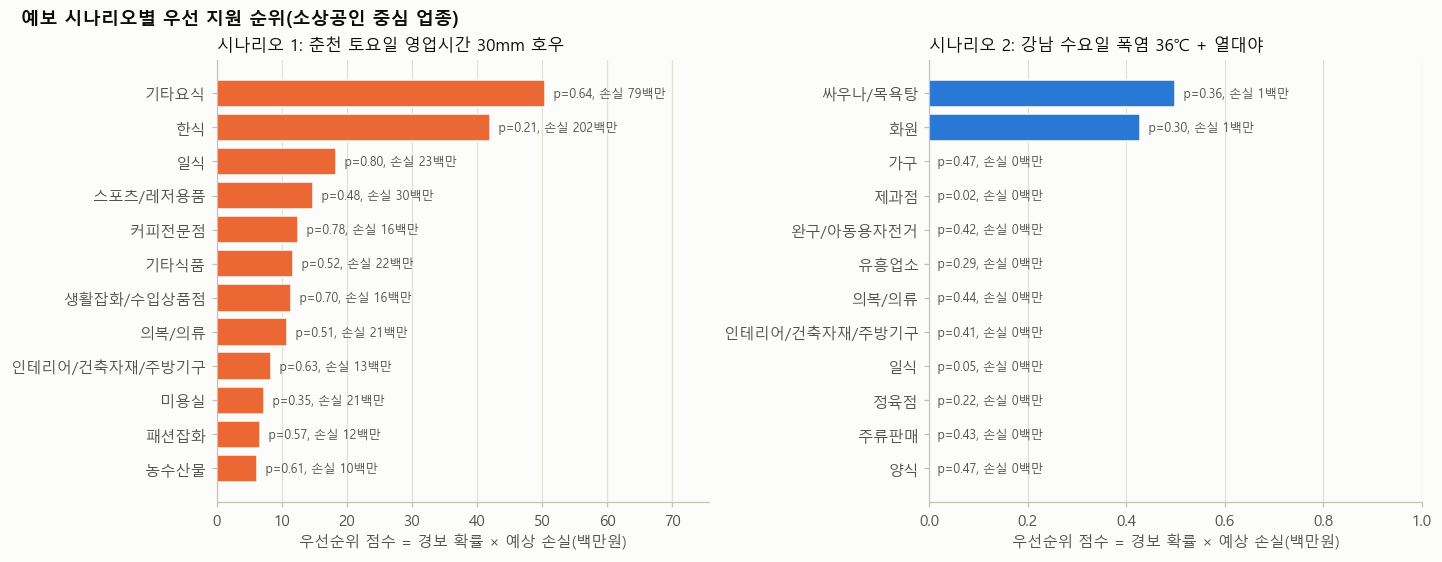

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, (s, ttl) in zip(axes, [(S1, "시나리오 1: 춘천 토요일 영업시간 30mm 호우"), (S2, "시나리오 2: 강남 수요일 폭염 36℃ + 열대야")]):
    t = s[s.small_biz == 1].head(12)
    ax.barh(range(len(t)), t.priority / 1e6, color=[REGION_COLOR[str(r)] for r in t.region], edgecolor=SURFACE)
    for i, (p, l) in enumerate(zip(t.p_alert, t.expected_loss)):
        ax.text(t.priority.iloc[i] / 1e6, i, f"  p={p:.2f}, 손실 {l/1e6:.0f}백만", va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(len(t)), t.industry); ax.invert_yaxis(); ax.set_title(ttl); ax.set_xlabel("우선순위 점수 = 경보 확률 × 예상 손실(백만원)"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(t.priority.max() / 1e6 * 1.5, 1))
finish(fig, FIG, "m03_priority", "예보 시나리오별 우선 지원 순위(소상공인 중심 업종)")
plt.show()

## 요약

- 예측 모델: 월 단위 교차검증·앞으로 예측 성능(`m_cv_month.csv`, `m_forward.csv`). 날씨 피처는 이벤트일(특히 비 온 날) 오차와 편향을 줄인다.
- 분류 모델: 이벤트일 10%+ 감소 경보의 ROC-AUC·PR-AUC(`m_cls_metrics.csv`), 단순 규칙 대비 개선.
- 우선순위: 시나리오별 순위표(`m_priority_*.csv`). 실제 운영에서는 기상청 단기예보(시간대별 강수량·기온)를 그대로 넣으면 된다.